In [1]:
import rasterio 
import matplotlib.pyplot as plt
import numpy as np
import pathlib

In [2]:
src = rasterio.open("/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_ndbi/WV02_250729_8bands_kandahar/25JUL29062634-S3DS-200009789240_01_P001.TIF")

In [3]:
arr=src.read()

In [8]:
arr.max()

255

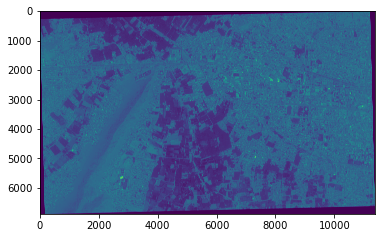

In [5]:
plt.imshow(arr[0])

NBEI = ( (NIR2 + NIR1) - (Green + RedEdge) )
       -------------------------------------
       ( (NIR2 + NIR1) + (Green + RedEdge) )

In [9]:
green = arr[2]/255
RedEdge = arr[5]/255
nir1 = arr[6]/255
nir2=arr[7]/255

In [10]:
NBEI = ((nir2+nir1)-(green+RedEdge))/((nir2+nir1)+(green+RedEdge))

/tmp/ipykernel_222662/3259722069.py:1: RuntimeWarning: invalid value encountered in true_divide
  NBEI = ((nir2+nir1)-(green+RedEdge))/((nir2+nir1)+(green+RedEdge))


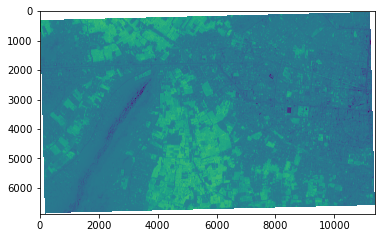

In [11]:
plt.imshow(NBEI)

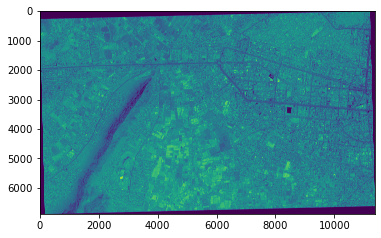

In [22]:
plt.imshow(nir1)

In [16]:
#|export

def save_raster(
    img:np.ndarray , # ndarray image
    number_of_bands: int , #number of  bands
    transf:tuple ,#transform function of the raster
    paths:str ,#save path raster
    tiff_name:str ,#name of specific file
    crs_img:rasterio.crs.CRS,
    ):  
    
    '''
    Function to save raster in requested path

    '''

    savedir=pathlib.Path(paths)
    savedir.mkdir(parents=True,exist_ok=True)


    with rasterio.open(savedir /tiff_name, 
                                   'w',
                                   driver='COG',
                                   height=img.shape[1],
                                   width=img.shape[2],
                                   count=number_of_bands,
                                   dtype=img.dtype,
                                   crs=crs_img,
                                   nodata=None, # change if data has nodata value
                                   transform=transf) as dst:

            for n in np.arange(0,number_of_bands):
                  dst.write(img[n,:,:],int(n+1))   
                    
    return None

In [39]:
NBEI.shape

(6877, 11360)

In [13]:
NBEI_new = NBEI.reshape(1, *NBEI.shape)


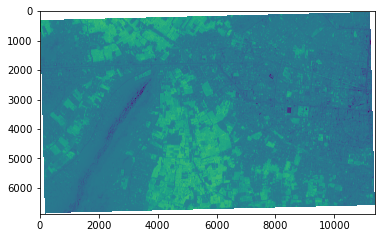

In [14]:
plt.imshow(NBEI_new[0,:,:])

In [17]:
save_raster(
    img=NBEI_new,
    number_of_bands=1,
    transf= src.transform,
    paths = "/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_ndbi/WV02_250729_8bands_kandahar",
    tiff_name="NBEI2.tif",
    crs_img = src.crs)

In [23]:
built_up_mask = (NBEI >= 0.03) & (NBEI <= 0.509)

binary_built_up = built_up_mask.astype(int)

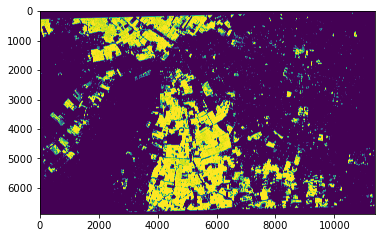

In [24]:
plt.imshow(binary_built_up)

In [28]:
NBEI_maksed = binary_built_up.reshape(1, *binary_built_up.shape)
NBEI_maksed =NBEI_maksed.astype(float)

In [30]:
NBEI_maksed

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]])

In [31]:
save_raster(
    img=NBEI_maksed,
    number_of_bands=1,
    transf= src.transform,
    paths = "/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_ndbi/WV02_250729_8bands_kandahar",
    tiff_name="NBEI2_MASK.tif",
    crs_img = src.crs)

In [34]:
import geopandas as gpd

gdf = gpd.read_file("/home/jovyan/work/predictions/afghanistan/kandahar_2025/test_small/KNLK2024/geojson/predicted_buildings.geojson")

gdf.to_file("/home/jovyan/work/predictions/afghanistan/kandahar_2025/test_small/KNLK2024/geojson/KNLK2024.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [36]:
import geopandas as gpd
from buildingregulariser import regularize_geodataframe